# Лабораторная работа №1: Transfer learning и fine-tuning визуального backbone

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/lab1/`.


## Цели обучения

После работы студент должен уметь:

- Подготовить CIFAR-10 или собственный малый датасет без утечки связанных объектов.
- Сравнить frozen, partial и full fine-tuning ResNet18.
- Построить confusion matrix и проверить corruption shift.


## Теоретическая часть

Предобученный backbone реализует отображение $f_\theta(x)=z$. Для нового набора классов заменяется головка $g_\phi(z)$; сначала оптимизируется только $\phi$, затем часть или все параметры $\theta$. Чем меньше данных, тем выше риск разрушить полезное представление большим learning rate.

![Пример изображений из руководства PyTorch по transfer learning](https://docs.pytorch.org/tutorials/_images/sphx_glr_transfer_learning_tutorial_001.png)

Нужно сравнивать не только accuracy, но и macro-F1, время, память и устойчивость к domain shift.


### Математическая постановка

Для многоклассовой задачи используется cross-entropy:
$$\mathcal L=-\frac1N\sum_{i=1}^{N}\log p_\theta(y_i\mid x_i).$$
Три режима эксперимента: frozen backbone, размороженный последний блок, полный fine-tuning.


### Материалы

- [PyTorch Transfer Learning Tutorial](https://pytorch.org/tutorials/beginner/transfer_learning_tutorial.html)
- [torchvision models](https://pytorch.org/vision/stable/models.html)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Подготовить CIFAR-10 или собственный малый датасет без утечки связанных объектов.
2. Сравнить frozen, partial и full fine-tuning ResNet18.
3. Построить confusion matrix и проверить corruption shift.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** ResNet18, FP32/FP16, 32–224 px.
- **Ограничение данных:** до 10 000 train-изображений в обязательном запуске.
- **Fallback:** CPU/FAST_DEV_RUN на подвыборке.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [1]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np

SEED = 42
FAST_DEV_RUN = False  # True — только проверка связности на уменьшенной выборке; не отчётный результат
# У каждой лабы своя папка: artifacts/lab1 — метрики, отчёты и checkpoints этой работы
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts/lab1"))
ARTIFACTS.mkdir(parents=True, exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch = None
    DEVICE = "cpu"
# CIFAR-10 общий для курса и лежит в data/cifar-10-batches-py, поэтому torchvision root = data
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA", "data"))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "artifacts": str(ARTIFACTS), "data_root": str(DATA_ROOT)})


{'device': 'cuda', 'fast_dev_run': False, 'artifacts': 'artifacts\\lab1', 'data_root': 'data'}


In [2]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Задание 1. Разделение CIFAR-10

*Вес: 1 балл.*

**Постановка.** Изоляция test необходима для оценки обобщения без подбора по тестовым меткам.

Выполните следующие действия:
1. Загрузите CIFAR-10 и разделите train на стратифицированные train и validation.
2. Подготовьте DataLoader с детерминированным test-преобразованием.

**Результат.** Непересекающиеся train, validation и test и загрузчики train_loader, val_loader, test_loader.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


CIFAR-10 — набор из 60 000 цветных картинок 32×32 в 10 классах: 50 000 для обучения и 10 000 для теста.<br>
Стратифицированное разбиение train/validation — деление данных на обучающую и проверочную части с сохранением доли каждого класса.<br>
DataLorder — порядок подачи примеров модели при обучении; его перемешивают и фиксируют через seed для воспроизводимости.<br>
Детерминированное тестовое преобразование — обработка тестовых картинок без случайных аугментаций, поэтому одна картинка всегда даёт один и тот же тензор.<br>
Аугментации — это случайные изменения обучающих картинок (отражение, сдвиг, обрезка, изменение яркости), которые искусственно увеличивают разнообразие данных и помогают модели меньше переобучаться.<br>
Тензор — это многомерный массив чисел, основной тип данных в PyTorch. Например, картинка CIFAR-10 превращается в тензор размера 3×32×32: три цветовых канала (RGB), в каждом 32×32 пикселя.

In [3]:
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

NUM_CLASSES = 10
IMG_SIZE = 64 if FAST_DEV_RUN else 128
BATCH_SIZE = 32 if FAST_DEV_RUN else 128
# Профиль вычислений: до 10 000 train-изображений в обязательном запуске
N_TRAIN = 500 if FAST_DEV_RUN else 10_000
N_VAL = 200 if FAST_DEV_RUN else 2_000
N_TEST = 200 if FAST_DEV_RUN else 10_000
# Возможность параллельной загрузки данных
NUM_WORKERS = 0 if os.name == "nt" else 2

# Backbone предобучен на ImageNet, поэтому нормализация — по его статистикам
# Средняя яркость каждого канала, разброс яркости каждого канала
IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
# Цепочка преобразований для каждой train картинки
train_tf = transforms.Compose([
    # Увеличение картинки
    transforms.Resize(IMG_SIZE),
    # Добавляем по краям черную рамку.
    # Вырезает случайный квадрат IMG_SIZE x IMG_SIZE
    transforms.RandomCrop(IMG_SIZE, padding=IMG_SIZE // 8),
    # с вероятностью 50 % отражает картинку слева направо
    transforms.RandomHorizontalFlip(),
    # превращает картинку в тензор формы (3, 128, 128) и переводит значения пикселей из диапазона 0–255 в 0–1.
    transforms.ToTensor(),
    # вычитает среднее и делит на стандартное отклонение по каждому каналу.
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
# Детерминированное преобразование для validation и test: без случайных аугментаций
test_tf = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

_download = not (DATA_ROOT / "cifar-10-batches-py").exists()
# Один и тот же исходный train в двух копиях: с аугментациями (для обучения) и без них (для validation)
full_train_aug = datasets.CIFAR10(DATA_ROOT, train=True, transform=train_tf, download=_download)
full_train_eval = datasets.CIFAR10(DATA_ROOT, train=True, transform=test_tf, download=False)
full_test = datasets.CIFAR10(DATA_ROOT, train=False, transform=test_tf, download=False)
CLASS_NAMES = full_train_aug.classes

# Стратифицированное разбиение: доли классов в train и validation совпадают с исходными
# Достаем метки классов
train_targets = np.array(full_train_aug.targets)
# train_idx — 10 000 номеров картинок для train;
# val_idx — 2 000 номеров картинок для validation.
train_idx, val_idx = train_test_split(
    np.arange(len(train_targets)),
    train_size=N_TRAIN,
    test_size=N_VAL,
    stratify=train_targets,
    random_state=SEED,
)
train_idx, val_idx = np.sort(train_idx), np.sort(val_idx)

test_targets = np.array(full_test.targets)
if N_TEST < len(test_targets):
    test_idx, _ = train_test_split(
        np.arange(len(test_targets)), train_size=N_TEST, stratify=test_targets, random_state=SEED
    )
    test_idx = np.sort(test_idx)
else:
    test_idx = np.arange(len(test_targets))

# Subset(набор, номера)
train_ds = Subset(full_train_aug, train_idx.tolist())
val_ds = Subset(full_train_eval, val_idx.tolist())
test_ds = Subset(full_test, test_idx.tolist())

_g = torch.Generator().manual_seed(SEED)
_pin = DEVICE == "cuda"
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, generator=_g,
                          num_workers=NUM_WORKERS, pin_memory=_pin)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=_pin)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=_pin)

# Считаем количество картинок каждого класса в train, validation и test
train_counts = np.bincount(train_targets[train_idx], minlength=NUM_CLASSES)
val_counts = np.bincount(train_targets[val_idx], minlength=NUM_CLASSES)
test_counts = np.bincount(test_targets[test_idx], minlength=NUM_CLASSES)

split_info = {
    "seed": SEED,
    "img_size": IMG_SIZE,
    "sizes": {"train": len(train_ds), "val": len(val_ds), "test": len(test_ds)},
    "class_counts": {
        "train": dict(zip(CLASS_NAMES, train_counts.tolist())),
        "val": dict(zip(CLASS_NAMES, val_counts.tolist())),
        "test": dict(zip(CLASS_NAMES, test_counts.tolist())),
    },
    "train_idx": train_idx.tolist(),
    "val_idx": val_idx.tolist(),
    "test_idx": test_idx.tolist(),
}
(ARTIFACTS / "split.json").write_text(json.dumps(split_info, ensure_ascii=False), encoding="utf-8")
print(json.dumps({k: split_info[k] for k in ("sizes", "class_counts")}, ensure_ascii=False, indent=2))

check(len(set(train_idx.tolist()) & set(val_idx.tolist())) == 0, "train и validation не пересекаются")
check(len(train_ds) <= 10_000, "train укладывается в ограничение 10 000 изображений")
check(train_counts.max() - train_counts.min() <= 1, "train стратифицирован: классы представлены поровну")
check(val_counts.max() - val_counts.min() <= 1, "validation стратифицирован: классы представлены поровну")
xb, yb = next(iter(val_loader))
check(tuple(xb.shape[1:]) == (3, IMG_SIZE, IMG_SIZE), f"батч имеет форму (3, {IMG_SIZE}, {IMG_SIZE})")
check(torch.equal(val_ds[0][0], val_ds[0][0]), "test-преобразование детерминировано")

{
  "sizes": {
    "train": 10000,
    "val": 2000,
    "test": 10000
  },
  "class_counts": {
    "train": {
      "airplane": 1000,
      "automobile": 1000,
      "bird": 1000,
      "cat": 1000,
      "deer": 1000,
      "dog": 1000,
      "frog": 1000,
      "horse": 1000,
      "ship": 1000,
      "truck": 1000
    },
    "val": {
      "airplane": 200,
      "automobile": 200,
      "bird": 200,
      "cat": 200,
      "deer": 200,
      "dog": 200,
      "frog": 200,
      "horse": 200,
      "ship": 200,
      "truck": 200
    },
    "test": {
      "airplane": 1000,
      "automobile": 1000,
      "bird": 1000,
      "cat": 1000,
      "deer": 1000,
      "dog": 1000,
      "frog": 1000,
      "horse": 1000,
      "ship": 1000,
      "truck": 1000
    }
  }
}
✔ train и validation не пересекаются
✔ train укладывается в ограничение 10 000 изображений
✔ train стратифицирован: классы представлены поровну
✔ validation стратифицирован: классы представлены поровну
✔ батч имеет форму

### Задание 2. Backbone и функции обучения

*Вес: 1 балл.*

**Постановка.** Режимы заморозки изменяют множество обновляемых параметров. Сравнивать их можно лишь при одинаковой функции потерь.

Выполните следующие действия:
1. Создайте ResNet18(рез-нет восемнадцать) с новой десятиклассовой головой.
2. Определите функции обучения и вычисления accuracy, macro-F1, матрицы ошибок.

**Результат.** Функции build_model, train_epoch и evaluate.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


ResNet-18 — свёрточная нейросеть из 18 слоёв с «обходными» (residual) связями, которые помогают обучать глубокие сети; обычно её берут уже обученной на ImageNet.<br>
10-классовая голова — последний полносвязный слой, который заменяют на новый с 10 выходами, по одному на каждый класс CIFAR-10.<br>
Accuracy — доля правильно классифицированных примеров среди всех.<br>
Macro F1 — F1-мера (среднее гармоническое точности и полноты), посчитанная отдельно для каждого класса и затем усреднённая, так что все классы весят одинаково.<br>
Матрица ошибок (confusion matrix) — таблица, где строки — истинные классы, столбцы — предсказанные, а в клетках — число примеров; по диагонали стоят правильные ответы, вне её видно, какие классы модель путает между собой.<br>
Frozen (замороженный backbone) — все слои ResNet-18 заморожены, обучается только новая 10-классовая голова. Это самый быстрый режим, но признаки от ImageNet не подстраиваются под CIFAR-10.<br>
Partial fine-tuning (частичное дообучение) — размораживают последние блоки (например, layer4) вместе с головой, а ранние слои остаются замороженными. Это компромисс: высокоуровневые признаки подстраиваются под новую задачу, а базовые (края, текстуры) остаются от ImageNet.<br>
Full fine-tuning (полное дообучение) — обучаются все слои сети. Обычно этот режим даёт лучшую точность, но он самый долгий, требует маленького learning rate и легче переобучается.

In [4]:
import torch.nn as nn
from sklearn.metrics import confusion_matrix, f1_score
from torchvision import models

FREEZE_MODES = ("frozen", "partial", "full")
# Одна функция потерь для всех режимов — иначе их нельзя сравнивать
criterion = nn.CrossEntropyLoss()


def build_model(mode="full", pretrained=True):
    """ResNet18 с новой головой на NUM_CLASSES классов; mode задаёт, какие параметры обучаются."""
    if mode not in FREEZE_MODES:
        raise ValueError(f"mode должен быть одним из {FREEZE_MODES}, получено: {mode!r}")
    weights = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    model = models.resnet18(weights=weights)
    # Голова ImageNet на 1000 классов заменяется новой, со случайными весами
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    # frozen — обучается только голова; partial — голова и последний блок; full — все параметры
    trainable_prefixes = {"frozen": ("fc.",), "partial": ("layer4.", "fc."), "full": ("",)}[mode]
    # Включаем нужный режим для обучения модели
    for name, param in model.named_parameters():
        param.requires_grad = name.startswith(trainable_prefixes)
    return model.to(DEVICE)


def count_params(model):
    """Число обучаемых и всех параметров модели."""
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    return trainable, total


def train_epoch(model, loader, optimizer, criterion=criterion, device=DEVICE):
    """Одна эпоха обучения; возвращает средний loss и accuracy на train."""
    model.train()
    # Замороженные BatchNorm оставляем в eval, чтобы их накопленные статистики не менялись
    for module in model.modules():
        if isinstance(module, nn.modules.batchnorm._BatchNorm) and not module.weight.requires_grad:
            module.eval()
    total_loss, correct, seen = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * yb.size(0)
        correct += (logits.argmax(dim=1) == yb).sum().item()
        seen += yb.size(0)
    return {"loss": total_loss / seen, "accuracy": correct / seen}


@torch.no_grad()
def evaluate(model, loader, criterion=criterion, device=DEVICE):
    """Оценка без обновления весов: loss, accuracy, macro-F1, матрица ошибок и сами предсказания."""
    model.eval()
    total_loss, seen = 0.0, 0
    y_true, y_pred = [], []
    for xb, yb in loader:
        xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
        logits = model(xb)
        total_loss += criterion(logits, yb).item() * yb.size(0)
        seen += yb.size(0)
        y_true.append(yb.cpu().numpy())
        y_pred.append(logits.argmax(dim=1).cpu().numpy())
    y_true, y_pred = np.concatenate(y_true), np.concatenate(y_pred)
    labels = list(range(NUM_CLASSES))
    return {
        "loss": total_loss / seen,
        "accuracy": float((y_true == y_pred).mean()),
        "macro_f1": float(f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)),
        # Строки — истинные классы, столбцы — предсказанные
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=labels),
        "y_true": y_true,
        "y_pred": y_pred,
    }


# Проверка без обучения: голова заменена, заморозка работает, прямой проход даёт 10 оценок на картинку
_model = build_model("frozen")
check(_model.fc.out_features == NUM_CLASSES, f"голова выдаёт {NUM_CLASSES} классов")
check(all(n.startswith("fc.") for n, p in _model.named_parameters() if p.requires_grad),
      "в режиме frozen обучается только голова")
_xb, _ = next(iter(val_loader))
with torch.no_grad():
    _out = _model.eval()(_xb[:4].to(DEVICE))
check(tuple(_out.shape) == (4, NUM_CLASSES), f"прямой проход даёт форму (4, {NUM_CLASSES})")
for _mode in FREEZE_MODES:
    _trainable, _total = count_params(build_model(_mode, pretrained=False))
    print(f"{_mode:8s} обучаемых параметров: {_trainable:>10,} из {_total:,}")
del _model, _xb, _out

✔ голова выдаёт 10 классов
✔ в режиме frozen обучается только голова
✔ прямой проход даёт форму (4, 10)
frozen   обучаемых параметров:      5,130 из 11,181,642
partial  обучаемых параметров:  8,398,858 из 11,181,642
full     обучаемых параметров: 11,181,642 из 11,181,642


### Задание 3. Режимы fine-tuning

*Вес: 1 балл.*

**Постановка.** Валидация определяет режим разморозки до первого обращения к test.

Выполните следующие действия:
1. Обучите frozen, partial и full при одинаковом числе эпох.
2. Сохраните веса и метрики validation; выберите режим по macro-F1.

**Результат.** Файлы resnet18_*.pt и metrics.json с измеренными validation-метриками.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Эпоха — один полный проход модели по всей обучающей выборке: каждый пример из train она увидела ровно один раз. Например, при 50 000 картинок и батче 64 одна эпоха — это около 782 шагов обучения.

In [5]:
EPOCHS = 1 if FAST_DEV_RUN else 5
# Голова обучается с нуля, поэтому шаг у неё больше; предобученным слоям — малый шаг, чтобы не разрушить признаки
LR_HEAD, LR_BACKBONE, WEIGHT_DECAY = 1e-3, 1e-4, 1e-4
# Общий бюджет для всех режимов; checkpoint с другой конфигурацией не продолжается
TRAIN_CONFIG = {
    "seed": SEED, "fast_dev_run": FAST_DEV_RUN, "img_size": IMG_SIZE, "batch_size": BATCH_SIZE,
    "n_train": len(train_ds), "n_val": len(val_ds),
    "optimizer": "AdamW", "lr_head": LR_HEAD, "lr_backbone": LR_BACKBONE, "weight_decay": WEIGHT_DECAY,
}


def make_optimizer(model, head_prefix="fc."):
    """AdamW по обучаемым параметрам: отдельные learning rate для головы и для backbone."""
    named = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
    groups = [{"params": [p for n, p in named if n.startswith(head_prefix)], "lr": LR_HEAD}]
    backbone = [p for n, p in named if not n.startswith(head_prefix)]
    if backbone:
        groups.append({"params": backbone, "lr": LR_BACKBONE})
    return torch.optim.AdamW(groups, weight_decay=WEIGHT_DECAY)


def save_atomic(obj, path):
    """Запись через временный файл: при сбое посреди сохранения прежний файл остаётся целым."""
    tmp_path = path.with_name(path.name + ".tmp")
    with open(tmp_path, "wb") as f:
        torch.save(obj, f)
        # Данные сбрасываются на диск до подмены файла, иначе при выключении питания файл может остаться пустым
        f.flush()
        os.fsync(f.fileno())
    for _ in range(5):
        try:
            os.replace(tmp_path, path)
            return
        except PermissionError:
            # OneDrive или антивирус могут ненадолго держать файл открытым
            time.sleep(1)
    os.replace(tmp_path, path)


def load_or_none(path):
    """Читает файл PyTorch; отсутствующий или повреждённый файл даёт None вместо ошибки."""
    if not path.exists():
        return None
    try:
        return torch.load(path, map_location=DEVICE, weights_only=True)
    except Exception as error:
        print(f"{path.name} повреждён и не используется ({type(error).__name__})")
        return None


def fit(model, tag, epochs=EPOCHS, head_prefix="fc."):
    """Обучение с checkpoint после каждой эпохи; лучшие по validation macro-F1 веса сохраняются в {tag}.pt."""
    ckpt_path, weights_path = ARTIFACTS / f"ckpt_{tag}.pt", ARTIFACTS / f"{tag}.pt"
    optimizer = make_optimizer(model, head_prefix)
    state = {"epoch": 0, "history": [], "best_f1": -1.0, "best_epoch": 0, "train_time_sec": 0.0, "peak_mem_mb": 0.0}

    # Продолжение после перезапуска: только если оба файла читаются и checkpoint получен с той же конфигурацией.
    # Иначе обучение начинается с первой эпохи, и файлы будут перезаписаны.
    ckpt = load_or_none(ckpt_path)
    if ckpt is not None and load_or_none(weights_path) is not None:
        if ckpt["config"] == TRAIN_CONFIG and ckpt["state"]["epoch"] <= epochs:
            model.load_state_dict(ckpt["model"])
            optimizer.load_state_dict(ckpt["optimizer"])
            state = ckpt["state"]
            print(f"[{tag}] найден checkpoint: пройдено эпох {state['epoch']} из {epochs}")
    del ckpt

    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()
    for epoch in range(state["epoch"] + 1, epochs + 1):
        # Seed зависит от номера эпохи: порядок батчей и аугментации одинаковы для всех режимов и после перезапуска
        torch.manual_seed(SEED + epoch)
        train_loader.generator.manual_seed(SEED + epoch)
        start = time.perf_counter()
        train_metrics = train_epoch(model, train_loader, optimizer)
        epoch_time = time.perf_counter() - start
        val_metrics = evaluate(model, val_loader)

        state["epoch"] = epoch
        state["train_time_sec"] += epoch_time
        if DEVICE == "cuda":
            state["peak_mem_mb"] = max(state["peak_mem_mb"], torch.cuda.max_memory_allocated() / 2**20)
        state["history"].append({
            "epoch": epoch,
            "train_loss": train_metrics["loss"], "train_accuracy": train_metrics["accuracy"],
            "val_loss": val_metrics["loss"], "val_accuracy": val_metrics["accuracy"],
            "val_macro_f1": val_metrics["macro_f1"], "epoch_time_sec": epoch_time,
        })
        if val_metrics["macro_f1"] > state["best_f1"]:
            state["best_f1"], state["best_epoch"] = val_metrics["macro_f1"], epoch
            save_atomic(model.state_dict(), weights_path)
        save_atomic({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                     "state": state, "config": TRAIN_CONFIG}, ckpt_path)
        print(f"[{tag}] эпоха {epoch}/{epochs}: train loss {train_metrics['loss']:.4f}, "
              f"val acc {val_metrics['accuracy']:.4f}, val macro-F1 {val_metrics['macro_f1']:.4f}, {epoch_time:.1f} с")

    # Итоговые метрики считаются на лучших сохранённых весах, а не на весах последней эпохи
    model.load_state_dict(torch.load(weights_path, map_location=DEVICE, weights_only=True))
    best = evaluate(model, val_loader)
    return {
        "weights": weights_path.name,
        "epochs": epochs,
        "best_epoch": state["best_epoch"],
        "val_loss": best["loss"],
        "val_accuracy": best["accuracy"],
        "val_macro_f1": best["macro_f1"],
        "val_confusion_matrix": best["confusion_matrix"].tolist(),
        "train_time_sec": state["train_time_sec"],
        "peak_mem_mb": state["peak_mem_mb"],
        "history": state["history"],
    }


# Три режима при одинаковом бюджете; test здесь не используется
results = {}
for mode in FREEZE_MODES:
    # Одинаковый seed перед созданием модели — одинаковые начальные веса головы во всех режимах
    torch.manual_seed(SEED)
    model = build_model(mode)
    trainable, total = count_params(model)
    results[mode] = {"trainable_params": trainable, "total_params": total, **fit(model, f"resnet18_{mode}")}
    del model
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

# Режим выбирается по validation macro-F1
BEST_MODE = max(results, key=lambda m: results[m]["val_macro_f1"])
metrics = {
    "config": {**TRAIN_CONFIG, "epochs": EPOCHS},
    "selection_metric": "val_macro_f1",
    "best_mode": BEST_MODE,
    "modes": results,
}
(ARTIFACTS / "metrics.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8")

print(f"\n{'режим':8s} {'val acc':>8s} {'macro-F1':>9s} {'лучшая эпоха':>13s} {'время, с':>9s} {'обучаемых параметров':>21s}")
for mode, r in results.items():
    print(f"{mode:8s} {r['val_accuracy']:8.4f} {r['val_macro_f1']:9.4f} {r['best_epoch']:13d} "
          f"{r['train_time_sec']:9.1f} {r['trainable_params']:21,}")
print(f"Выбран режим: {BEST_MODE}")

check(all((ARTIFACTS / f"resnet18_{m}.pt").exists() for m in FREEZE_MODES), "веса трёх режимов сохранены в resnet18_*.pt")
check(all(len(results[m]["history"]) == EPOCHS for m in FREEZE_MODES), f"все режимы обучены одинаковое число эпох: {EPOCHS}")
check((ARTIFACTS / "metrics.json").exists(), "validation-метрики сохранены в metrics.json")

[resnet18_frozen] найден checkpoint: пройдено эпох 5 из 5
[resnet18_partial] найден checkpoint: пройдено эпох 5 из 5
[resnet18_full] найден checkpoint: пройдено эпох 5 из 5

режим     val acc  macro-F1  лучшая эпоха  время, с  обучаемых параметров
frozen     0.7945    0.7914             4      49.3                 5,130
partial    0.8900    0.8902             5      49.9             8,398,858
full       0.9220    0.9221             4      67.7            11,181,642
Выбран режим: full
✔ веса трёх режимов сохранены в resnet18_*.pt
✔ все режимы обучены одинаковое число эпох: 5
✔ validation-метрики сохранены в metrics.json


### Задание 4. Альтернативная архитектура и отложенный тест

*Вес: 1 балл.*

**Постановка.** Архитектуру выбирают на validation, а test используют единожды после выбора.

Выполните следующие действия:
1. Обучите EfficientNet-B0 (Эфи́шент-нет би-ноль) при том же бюджете.
2. Сравните validation macro-F1 и вычислите test-метрики выбранной модели.

**Результат.** backbone_comparison.json и test_metrics.json.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [6]:
def build_efficientnet(mode="full", pretrained=True):
    """EfficientNet-B0 с новой головой на NUM_CLASSES классов; режимы заморозки те же, что у ResNet18."""
    if mode not in FREEZE_MODES:
        raise ValueError(f"mode должен быть одним из {FREEZE_MODES}, получено: {mode!r}")
    weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
    model = models.efficientnet_b0(weights=weights)
    # Голова здесь — classifier = [Dropout, Linear]; заменяется только последний Linear
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
    # partial — голова, последний блок features.7 и завершающая свёртка features.8
    trainable_prefixes = {
        "frozen": ("classifier.",),
        "partial": ("features.7.", "features.8.", "classifier."),
        "full": ("",),
    }[mode]
    for name, param in model.named_parameters():
        param.requires_grad = name.startswith(trainable_prefixes)
    return model.to(DEVICE)


# Тот же бюджет, что у ResNet18: те же данные, эпохи, оптимизатор и режим разморозки, выбранный на validation
torch.manual_seed(SEED)
model = build_efficientnet(BEST_MODE)
trainable, total = count_params(model)
eff_result = {"trainable_params": trainable, "total_params": total,
              **fit(model, f"efficientnet_b0_{BEST_MODE}", head_prefix="classifier.")}
del model
if DEVICE == "cuda":
    torch.cuda.empty_cache()

# Архитектура выбирается по validation macro-F1; test до этого момента не использовался
candidates = {
    "resnet18": {"mode": BEST_MODE, **results[BEST_MODE]},
    "efficientnet_b0": {"mode": BEST_MODE, **eff_result},
}
BEST_BACKBONE = max(candidates, key=lambda name: candidates[name]["val_macro_f1"])
comparison = {
    "config": {**TRAIN_CONFIG, "epochs": EPOCHS},
    "selection_metric": "val_macro_f1",
    "freeze_mode": BEST_MODE,
    "selected": BEST_BACKBONE,
    "backbones": candidates,
}
(ARTIFACTS / "backbone_comparison.json").write_text(json.dumps(comparison, ensure_ascii=False, indent=2), encoding="utf-8")

print(f"\n{'backbone':16s} {'val acc':>8s} {'macro-F1':>9s} {'время, с':>9s} {'память, МБ':>11s} {'всего параметров':>17s}")
for name, r in candidates.items():
    print(f"{name:16s} {r['val_accuracy']:8.4f} {r['val_macro_f1']:9.4f} {r['train_time_sec']:9.1f} "
          f"{r['peak_mem_mb']:11.0f} {r['total_params']:17,}")
print(f"Выбрана архитектура: {BEST_BACKBONE} (режим {BEST_MODE})")

# Единственное обращение к test: выбранная модель с лучшими по validation весами
_builders = {"resnet18": build_model, "efficientnet_b0": build_efficientnet}
final_model = _builders[BEST_BACKBONE](BEST_MODE, pretrained=False)
final_model.load_state_dict(
    torch.load(ARTIFACTS / candidates[BEST_BACKBONE]["weights"], map_location=DEVICE, weights_only=True)
)
test_result = evaluate(final_model, test_loader)
test_metrics = {
    "backbone": BEST_BACKBONE,
    "mode": BEST_MODE,
    "weights": candidates[BEST_BACKBONE]["weights"],
    "n_test": len(test_ds),
    "test_loss": test_result["loss"],
    "test_accuracy": test_result["accuracy"],
    "test_macro_f1": test_result["macro_f1"],
    "class_names": CLASS_NAMES,
    "confusion_matrix": test_result["confusion_matrix"].tolist(),
}
(ARTIFACTS / "test_metrics.json").write_text(json.dumps(test_metrics, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"test: accuracy {test_result['accuracy']:.4f}, macro-F1 {test_result['macro_f1']:.4f}, loss {test_result['loss']:.4f}")

check(len(eff_result["history"]) == EPOCHS, f"EfficientNet-B0 обучена столько же эпох, сколько ResNet18: {EPOCHS}")
check((ARTIFACTS / "backbone_comparison.json").exists(), "сравнение архитектур сохранено в backbone_comparison.json")
check((ARTIFACTS / "test_metrics.json").exists(), "test-метрики выбранной модели сохранены в test_metrics.json")

[efficientnet_b0_full] найден checkpoint: пройдено эпох 5 из 5

backbone          val acc  macro-F1  время, с  память, МБ  всего параметров
resnet18           0.9220    0.9221      67.7        1065        11,181,642
efficientnet_b0    0.9180    0.9180      90.9        3662         4,020,358
Выбрана архитектура: resnet18 (режим full)
test: accuracy 0.9052, macro-F1 0.9049, loss 0.2920
✔ EfficientNet-B0 обучена столько же эпох, сколько ResNet18: 5
✔ сравнение архитектур сохранено в backbone_comparison.json
✔ test-метрики выбранной модели сохранены в test_metrics.json


### Задание 5. Шумовой сдвиг и ошибки классификации

*Вес: 1 балл.*

**Постановка.** Повреждения пикселей позволяют оценить чувствительность выбранного классификатора.

Выполните следующие действия:
1. Примените шум к отложенным изображениям и измерьте accuracy.
2. Сохраните индексы фактических ошибочных предсказаний.

**Результат.** shift_metrics.json и errors.json с предсказаниями модели.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


✔ чистый и зашумлённый проходы идут по одним и тем же картинкам
accuracy на чистом test:       0.9052
accuracy при шуме sigma=0.1: 0.3144
падение accuracy:              0.5908
ошибок: 948 на чистом test, 6856 на зашумлённом

Самые частые ошибки при шуме (истинный → предсказанный):
         dog → cat         701
        frog → cat         617
        deer → cat         580
       truck → cat         504
       horse → cat         391


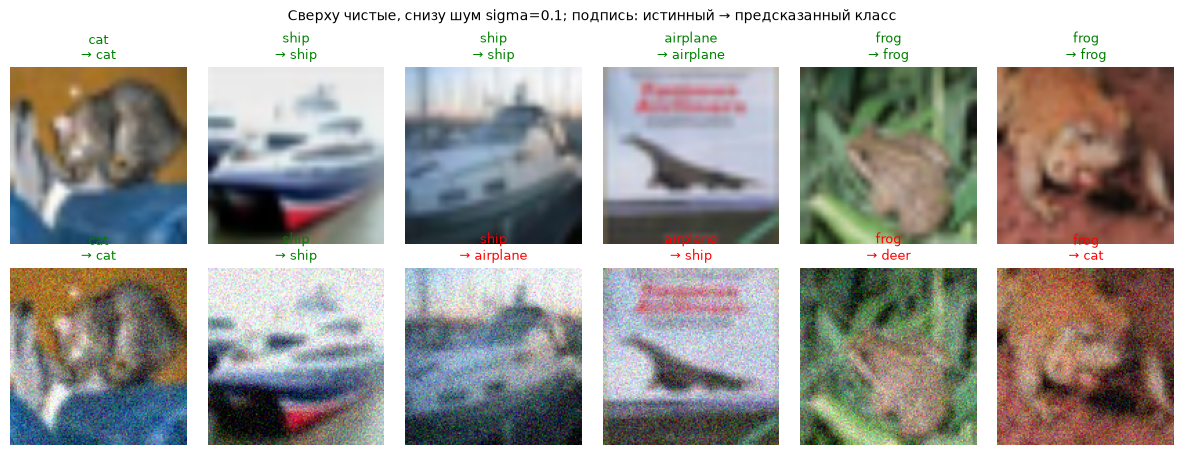

✔ метрики сдвига сохранены в shift_metrics.json
✔ индексы ошибочных предсказаний сохранены в errors.json
✔ число сохранённых ошибок согласуется с accuracy


In [7]:
import matplotlib.pyplot as plt

# Сила гауссовского шума в шкале пикселей 0–1 (0.1 — это около 25 из 255 уровней яркости)
NOISE_SIGMA = 0.1
_MEAN = torch.tensor(IMAGENET_MEAN, device=DEVICE).view(1, 3, 1, 1)
_STD = torch.tensor(IMAGENET_STD, device=DEVICE).view(1, 3, 1, 1)


def add_gaussian_noise(xb, sigma, generator):
    """Шум добавляется к пикселям в шкале 0–1: батч денормализуется, зашумляется, обрезается и нормализуется обратно."""
    pixels = xb * _STD + _MEAN
    noise = torch.randn(pixels.shape, generator=generator, device=pixels.device)
    return ((pixels + sigma * noise).clamp(0, 1) - _MEAN) / _STD


@torch.no_grad()
def predict(model, loader, sigma=0.0, seed=SEED):
    """Истинные и предсказанные классы; при sigma > 0 картинки зашумляются с фиксированным seed."""
    model.eval()
    # Генератор создаётся заново при каждом вызове: один и тот же рисунок шума для любых sigma
    generator = torch.Generator(device=DEVICE).manual_seed(seed)
    y_true, y_pred = [], []
    for xb, yb in loader:
        xb = xb.to(DEVICE, non_blocking=True)
        if sigma > 0:
            xb = add_gaussian_noise(xb, sigma, generator)
        y_true.append(yb.numpy())
        y_pred.append(model(xb).argmax(dim=1).cpu().numpy())
    return np.concatenate(y_true), np.concatenate(y_pred)


def error_records(y_true, y_pred):
    """Список ошибочных предсказаний: номер картинки в test CIFAR-10, истинный и предсказанный класс."""
    return [
        {"index": int(test_idx[pos]), "true": CLASS_NAMES[y_true[pos]], "pred": CLASS_NAMES[y_pred[pos]]}
        for pos in np.flatnonzero(y_true != y_pred)
    ]


# Чистые предсказания уже получены при единственной оценке на test; здесь считаются только зашумлённые
clean_true, clean_pred = test_result["y_true"], test_result["y_pred"]
noisy_true, noisy_pred = predict(final_model, test_loader, sigma=NOISE_SIGMA)
check(np.array_equal(clean_true, noisy_true), "чистый и зашумлённый проходы идут по одним и тем же картинкам")

_labels = list(range(NUM_CLASSES))
clean_acc, noisy_acc = float((clean_true == clean_pred).mean()), float((noisy_true == noisy_pred).mean())
shift_metrics = {
    "backbone": BEST_BACKBONE,
    "mode": BEST_MODE,
    "noise": {"type": "gaussian", "sigma": NOISE_SIGMA, "scale": "пиксели 0–1",
              "applied": f"после Resize до {IMG_SIZE} px, с обрезкой в 0–1", "seed": SEED},
    "n_test": len(test_ds),
    "clean_accuracy": clean_acc,
    "noisy_accuracy": noisy_acc,
    "accuracy_drop": clean_acc - noisy_acc,
    "clean_macro_f1": float(f1_score(clean_true, clean_pred, labels=_labels, average="macro", zero_division=0)),
    "noisy_macro_f1": float(f1_score(noisy_true, noisy_pred, labels=_labels, average="macro", zero_division=0)),
}
(ARTIFACTS / "shift_metrics.json").write_text(json.dumps(shift_metrics, ensure_ascii=False, indent=2), encoding="utf-8")

# Фактические ошибки модели на чистом и на зашумлённом test
errors = {
    "backbone": BEST_BACKBONE,
    "mode": BEST_MODE,
    "index_meaning": "номер картинки в официальном test CIFAR-10",
    "sigma": NOISE_SIGMA,
    "n_clean_errors": int((clean_true != clean_pred).sum()),
    "n_noisy_errors": int((noisy_true != noisy_pred).sum()),
    "clean": error_records(clean_true, clean_pred),
    "noisy": error_records(noisy_true, noisy_pred),
}
(ARTIFACTS / "errors.json").write_text(json.dumps(errors, ensure_ascii=False), encoding="utf-8")

print(f"accuracy на чистом test:       {clean_acc:.4f}")
print(f"accuracy при шуме sigma={NOISE_SIGMA}: {noisy_acc:.4f}")
print(f"падение accuracy:              {clean_acc - noisy_acc:.4f}")
print(f"ошибок: {errors['n_clean_errors']} на чистом test, {errors['n_noisy_errors']} на зашумлённом")

# Какие классы модель путает чаще всего на зашумлённых картинках
_cm = confusion_matrix(noisy_true, noisy_pred, labels=_labels)
np.fill_diagonal(_cm, 0)
print("\nСамые частые ошибки при шуме (истинный → предсказанный):")
for _flat in np.argsort(_cm, axis=None)[::-1][:5]:
    _t, _p = divmod(int(_flat), NUM_CLASSES)
    print(f"  {CLASS_NAMES[_t]:>10s} → {CLASS_NAMES[_p]:<10s} {_cm[_t, _p]:4d}")

# Первые картинки test: сверху чистые, снизу с тем же шумом, что использован при оценке
_n_show = 6
_xb, _ = next(iter(test_loader))
_clean = _xb.to(DEVICE)
_noisy = add_gaussian_noise(_clean, NOISE_SIGMA, torch.Generator(device=DEVICE).manual_seed(SEED))
fig, axes = plt.subplots(2, _n_show, figsize=(2 * _n_show, 4.6))
for _row, (_batch, _pred) in enumerate([(_clean, clean_pred), (_noisy, noisy_pred)]):
    _images = (_batch[:_n_show] * _STD + _MEAN).clamp(0, 1).permute(0, 2, 3, 1).cpu().numpy()
    for _col in range(_n_show):
        _ok = _pred[_col] == clean_true[_col]
        axes[_row, _col].imshow(_images[_col])
        axes[_row, _col].set_title(f"{CLASS_NAMES[clean_true[_col]]}\n→ {CLASS_NAMES[_pred[_col]]}",
                                   fontsize=9, color="green" if _ok else "red")
        axes[_row, _col].axis("off")
fig.suptitle(f"Сверху чистые, снизу шум sigma={NOISE_SIGMA}; подпись: истинный → предсказанный класс", fontsize=10)
plt.tight_layout()
plt.show()

check((ARTIFACTS / "shift_metrics.json").exists(), "метрики сдвига сохранены в shift_metrics.json")
check((ARTIFACTS / "errors.json").exists(), "индексы ошибочных предсказаний сохранены в errors.json")
check(len(errors["clean"]) == round((1 - clean_acc) * len(test_ds)), "число сохранённых ошибок согласуется с accuracy")

### Задание 6. Профиль устойчивости к шуму

*Вес: 1 балл.*

**Постановка.** Одна интенсивность повреждения не описывает характер деградации.

Выполните следующие действия:
1. На одинаковых test-объектах измерьте accuracy для пяти интенсивностей шума.
2. Сохраните профиль деградации.

**Результат.** sigma_sensitivity.json с измеренной точностью.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


 sigma  accuracy  падение  macro-F1
  0.00    0.9052   0.0000    0.9049   (чистый test)
  0.02    0.8564   0.0488    0.8573
  0.05    0.6783   0.2269    0.6873
  0.10    0.3144   0.5908    0.2804
  0.20    0.1585   0.7467    0.0794
  0.30    0.1022   0.8030    0.0235


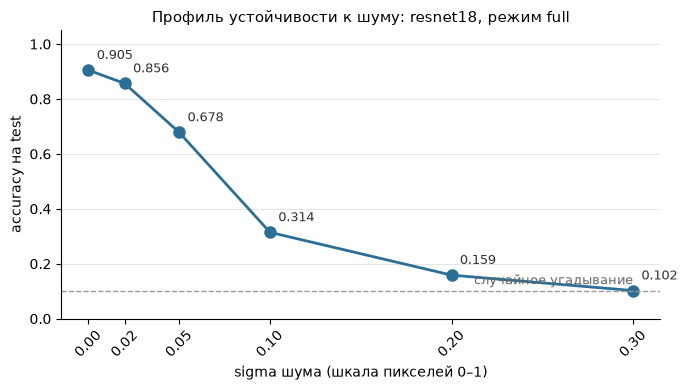

✔ accuracy измерена для пяти интенсивностей шума
✔ значение при sigma=0.1 совпадает с предыдущим заданием: шум воспроизводим
✔ профиль деградации сохранён в sigma_sensitivity.json


In [8]:
# Пять интенсивностей шума в шкале пикселей 0–1; среди них NOISE_SIGMA из предыдущего задания
SIGMAS = (0.02, 0.05, 0.1, 0.2, 0.3)

# Картинки и рисунок шума одинаковы для всех sigma (тот же test_loader и тот же seed), меняется только сила шума
sigma_preds = {}
profile = []
for sigma in SIGMAS:
    y_true, y_pred = predict(final_model, test_loader, sigma=sigma)
    sigma_preds[sigma] = y_pred
    accuracy = float((y_true == y_pred).mean())
    profile.append({
        "sigma": sigma,
        "accuracy": accuracy,
        "accuracy_drop": clean_acc - accuracy,
        "macro_f1": float(f1_score(y_true, y_pred, labels=_labels, average="macro", zero_division=0)),
    })

sigma_sensitivity = {
    "backbone": BEST_BACKBONE,
    "mode": BEST_MODE,
    "noise": {"type": "gaussian", "scale": "пиксели 0–1",
              "applied": f"после Resize до {IMG_SIZE} px, с обрезкой в 0–1", "seed": SEED},
    "n_test": len(test_ds),
    "clean_accuracy": clean_acc,
    "profile": profile,
}
(ARTIFACTS / "sigma_sensitivity.json").write_text(json.dumps(sigma_sensitivity, ensure_ascii=False, indent=2), encoding="utf-8")

print(f"{'sigma':>6s} {'accuracy':>9s} {'падение':>8s} {'macro-F1':>9s}")
print(f"{0.0:6.2f} {clean_acc:9.4f} {0.0:8.4f} {shift_metrics['clean_macro_f1']:9.4f}   (чистый test)")
for row in profile:
    print(f"{row['sigma']:6.2f} {row['accuracy']:9.4f} {row['accuracy_drop']:8.4f} {row['macro_f1']:9.4f}")

# Профиль деградации: точка sigma=0 — чистый test, пунктир — уровень случайного угадывания
_xs = [0.0] + [row["sigma"] for row in profile]
_ys = [clean_acc] + [row["accuracy"] for row in profile]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(_xs, _ys, marker="o", markersize=8, linewidth=2, color="#2a6f97")
for _x, _y in zip(_xs, _ys):
    ax.annotate(f"{_y:.3f}", (_x, _y), textcoords="offset points", xytext=(6, 8), fontsize=9, color="#333333")
ax.axhline(1 / NUM_CLASSES, color="#999999", linewidth=1, linestyle="--")
ax.annotate("случайное угадывание", (_xs[-1], 1 / NUM_CLASSES), textcoords="offset points",
            xytext=(0, 5), ha="right", fontsize=9, color="#666666")
ax.set_xlabel("sigma шума (шкала пикселей 0–1)")
ax.set_ylabel("accuracy на test")
ax.set_title(f"Профиль устойчивости к шуму: {BEST_BACKBONE}, режим {BEST_MODE}", fontsize=11)
ax.set_xticks(_xs)
ax.tick_params(axis="x", labelrotation=45)
ax.set_ylim(0, 1.05)
ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

check(len(profile) == 5, "accuracy измерена для пяти интенсивностей шума")
check(abs(next(r["accuracy"] for r in profile if r["sigma"] == NOISE_SIGMA) - noisy_acc) < 1e-9,
      f"значение при sigma={NOISE_SIGMA} совпадает с предыдущим заданием: шум воспроизводим")
check((ARTIFACTS / "sigma_sensitivity.json").exists(), "профиль деградации сохранён в sigma_sensitivity.json")

sigma_sensitivity.json: resnet18, режим full, 10000 test-картинок; sigma = 0 — чистый test


,accuracy,падение accuracy,macro-F1
sigma,,,
0.00,0.9052,0.0000,0.9049
0.02,0.8564,0.0488,0.8573
0.05,0.6783,0.2269,0.6873
0.10,0.3144,0.5908,0.2804
0.20,0.1585,0.7467,0.0794
0.30,0.1022,0.8030,0.0235


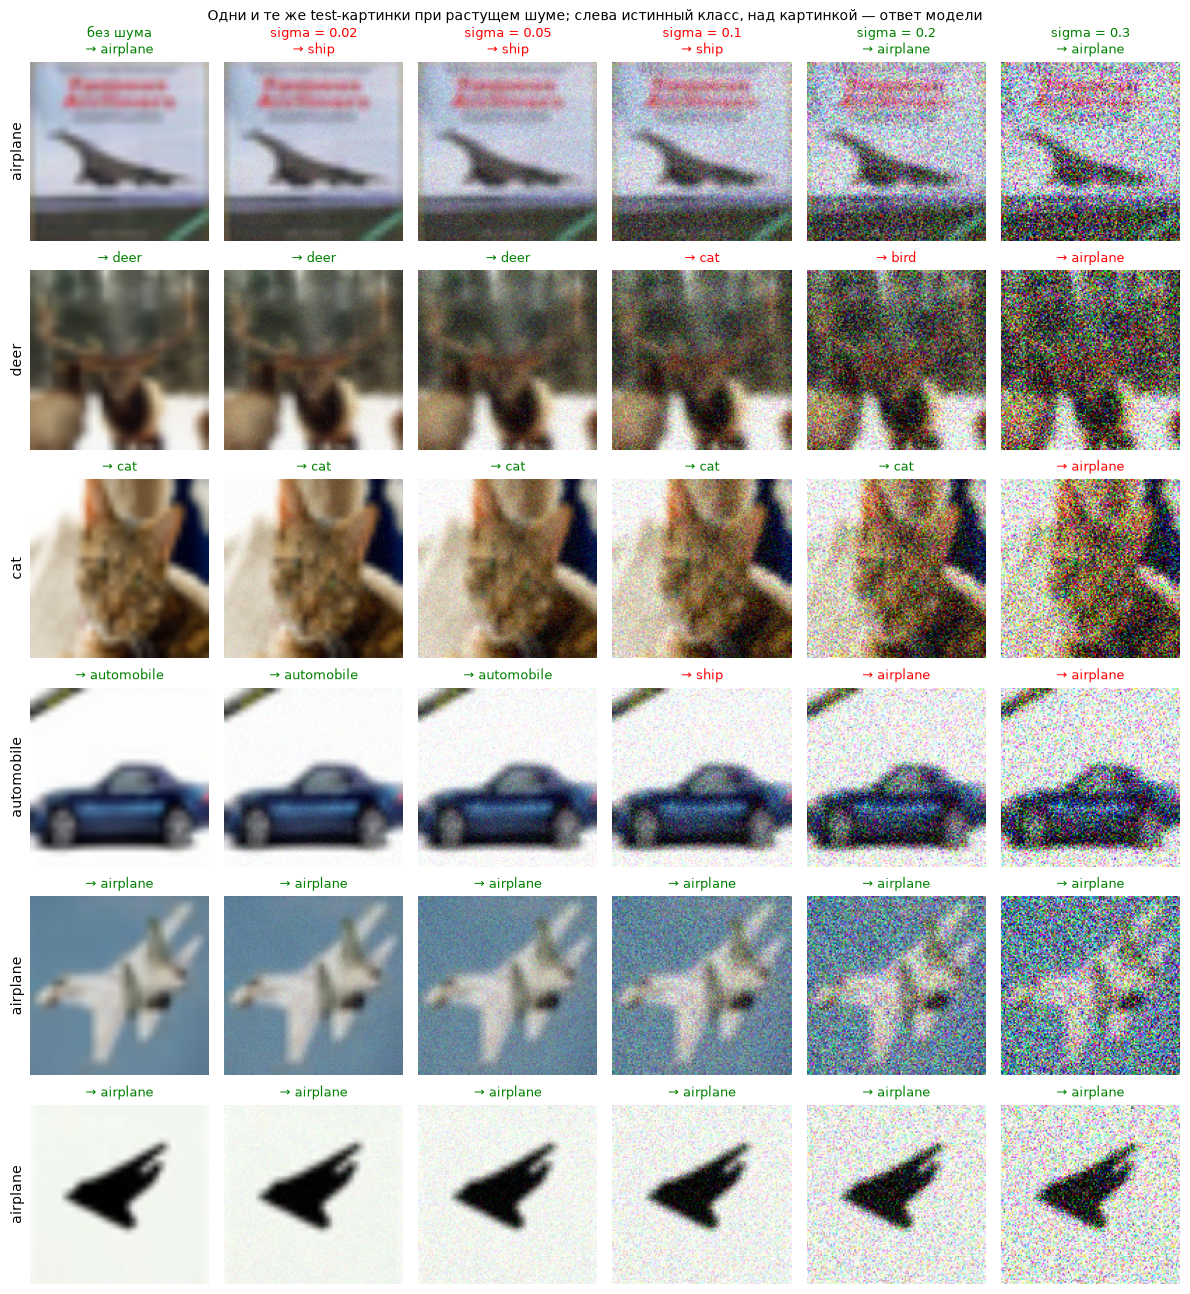

In [9]:
import pandas as pd
from IPython.display import display

# Содержимое sigma_sensitivity.json прямо в notebook: читаем сохранённый файл, а не переменные в памяти
_saved = json.loads((ARTIFACTS / "sigma_sensitivity.json").read_text(encoding="utf-8"))
_table = pd.DataFrame(
    [{"sigma": 0.0, "accuracy": _saved["clean_accuracy"], "accuracy_drop": 0.0, "macro_f1": shift_metrics["clean_macro_f1"]}]
    + _saved["profile"]
).set_index("sigma")
_table.columns = ["accuracy", "падение accuracy", "macro-F1"]
print(f"sigma_sensitivity.json: {_saved['backbone']}, режим {_saved['mode']}, {_saved['n_test']} test-картинок; sigma = 0 — чистый test")
display(_table.style.format("{:.4f}").format_index("{:.2f}").background_gradient(subset=["accuracy"], cmap="RdYlGn", vmin=0, vmax=1))

# Как модель видит одни и те же картинки при растущем шуме. Берём первую партию test:
# свежий генератор с SEED даёт для неё ровно тот шум, что был при оценке, поэтому подписи — настоящие предсказания
_xb, _ = next(iter(test_loader))
_clean = _xb.to(DEVICE)
_n_batch = len(_xb)
_levels = [0.0] + list(SIGMAS)
_truth = clean_true[:_n_batch]
_preds = np.stack([clean_pred[:_n_batch]] + [sigma_preds[s][:_n_batch] for s in SIGMAS])  # (уровень шума, картинка)
_correct = _preds == _truth

# Сначала картинки, которые без шума распознаны верно, а под шумом ломаются (на разных уровнях), затем устойчивые
_first_wrong = np.where(_correct, len(_levels), np.arange(len(_levels))[:, None]).min(axis=0)
_broken = np.flatnonzero(_correct[0] & ~_correct.all(axis=0))
_broken = _broken[np.argsort(_first_wrong[_broken], kind="stable")]
_pick = list(np.unique(_broken[np.linspace(0, len(_broken) - 1, min(4, len(_broken))).astype(int)])) if len(_broken) else []
_pick += [i for i in np.flatnonzero(_correct.all(axis=0)) if i not in _pick][:6 - len(_pick)]
_pick += [i for i in range(_n_batch) if i not in _pick][:6 - len(_pick)]

_images = []
for _s in _levels:
    _batch = _clean if _s == 0 else add_gaussian_noise(_clean, _s, torch.Generator(device=DEVICE).manual_seed(SEED))
    _images.append((_batch[_pick] * _STD + _MEAN).clamp(0, 1).permute(0, 2, 3, 1).cpu().numpy())

fig, axes = plt.subplots(len(_pick), len(_levels), figsize=(2 * len(_levels), 2.2 * len(_pick)), squeeze=False)
for _r, _i in enumerate(_pick):
    for _c, _s in enumerate(_levels):
        _ax = axes[_r, _c]
        _ax.imshow(_images[_c][_r])
        _p = _preds[_c, _i]
        _head = ("без шума" if _s == 0 else f"sigma = {_s}") + "\n" if _r == 0 else ""
        _ax.set_title(f"{_head}→ {CLASS_NAMES[_p]}", fontsize=9, color="green" if _p == _truth[_i] else "red")
        _ax.set_xticks([]); _ax.set_yticks([])
        _ax.spines[:].set_visible(False)
    axes[_r, 0].set_ylabel(CLASS_NAMES[_truth[_i]], fontsize=10)
fig.suptitle("Одни и те же test-картинки при растущем шуме; слева истинный класс, над картинкой — ответ модели", fontsize=10)
plt.tight_layout()
plt.show()

### Задание 7. Доля обучаемых параметров

*Вес: 1 балл.*

**Постановка.** Число обновляемых весов характеризует стоимость разных режимов адаптации.

Выполните следующие действия:
1. Посчитайте параметры каждого режима разморозки.
2. Проверьте порядок frozen, partial, full.

**Результат.** param_report.json с числами параметров трёх моделей.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [10]:
# Число параметров не зависит от значений весов, поэтому модели создаются без загрузки ImageNet
param_report = {"backbone": "resnet18", "modes": {}}
for mode in FREEZE_MODES:
    model = build_model(mode, pretrained=False)
    trainable, total = count_params(model)
    # Какие части сети обучаются в этом режиме: параметры по группам слоёв (conv1, bn1, layer1–layer4, fc)
    by_block = {}
    for name, param in model.named_parameters():
        if param.requires_grad:
            block = name.split(".")[0]
            by_block[block] = by_block.get(block, 0) + param.numel()
    param_report["modes"][mode] = {
        "trainable_params": trainable,
        "frozen_params": total - trainable,
        "total_params": total,
        "trainable_fraction": trainable / total,
        "trainable_by_block": by_block,
    }
    del model

_counts = [param_report["modes"][m]["trainable_params"] for m in FREEZE_MODES]
param_report["order_frozen_partial_full"] = bool(_counts[0] < _counts[1] < _counts[2])
(ARTIFACTS / "param_report.json").write_text(json.dumps(param_report, ensure_ascii=False, indent=2), encoding="utf-8")

print(f"{'режим':8s} {'обучаемых':>12s} {'заморожено':>12s} {'всего':>12s} {'доля обучаемых':>15s}")
for mode, r in param_report["modes"].items():
    print(f"{mode:8s} {r['trainable_params']:12,} {r['frozen_params']:12,} {r['total_params']:12,} "
          f"{r['trainable_fraction']:15.4%}")

print("\nОбучаемые параметры по группам слоёв в режиме full:")
for block, count in param_report["modes"]["full"]["trainable_by_block"].items():
    print(f"  {block:7s} {count:10,}  {count / param_report['modes']['full']['total_params']:7.2%}")

check(param_report["order_frozen_partial_full"], "обучаемых параметров: frozen < partial < full")
check(len({r["total_params"] for r in param_report["modes"].values()}) == 1,
      "общее число параметров одинаково во всех режимах: меняется только заморозка")
check(all(param_report["modes"][m]["trainable_params"] == results[m]["trainable_params"] for m in FREEZE_MODES),
      "числа совпадают с моделями, которые обучались в задании про режимы fine-tuning")
check((ARTIFACTS / "param_report.json").exists(), "отчёт сохранён в param_report.json")

режим       обучаемых   заморожено        всего  доля обучаемых
frozen          5,130   11,176,512   11,181,642         0.0459%
partial     8,398,858    2,782,784   11,181,642        75.1129%
full       11,181,642            0   11,181,642       100.0000%

Обучаемые параметры по группам слоёв в режиме full:
  conv1        9,408    0.08%
  bn1            128    0.00%
  layer1     147,968    1.32%
  layer2     525,568    4.70%
  layer3   2,099,712   18.78%
  layer4   8,393,728   75.07%
  fc           5,130    0.05%
✔ обучаемых параметров: frozen < partial < full
✔ общее число параметров одинаково во всех режимах: меняется только заморозка
✔ числа совпадают с моделями, которые обучались в задании про режимы fine-tuning
✔ отчёт сохранён в param_report.json


### Задание 8. Поклассовые ошибки

*Вес: 1 балл.*

**Постановка.** Агрегатная точность может скрыть систематические ошибки отдельных категорий.

Выполните следующие действия:
1. Вычислите recall для каждого класса по test confusion matrix.
2. Найдите класс с наименьшим recall.

**Результат.** class_report.json с поклассовым recall и худшим классом.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Recall (полнота) — доля объектов класса, которые модель нашла, среди всех объектов этого класса: recall = TP / (TP + FN). Например, recall для класса «кошка» = 0.8 значит, что модель узнала 80% всех кошек, а 20% отнесла к другим классам.

класс         recall  верно  всего   чаще всего путают с
cat           0.7720    772   1000   dog (112)
dog           0.8800    880   1000   cat (81)
deer          0.8870    887   1000   bird (32)
bird          0.8900    890   1000   frog (24)
ship          0.9130    913   1000   airplane (59)
horse         0.9170    917   1000   dog (30)
truck         0.9410    941   1000   automobile (41)
airplane      0.9440    944   1000   bird (16)
frog          0.9530    953   1000   bird (12)
automobile    0.9550    955   1000   truck (31)

Худший класс: cat, recall 0.7720 при общей accuracy 0.9052
Разброс recall между классами: от 0.7720 до 0.9550


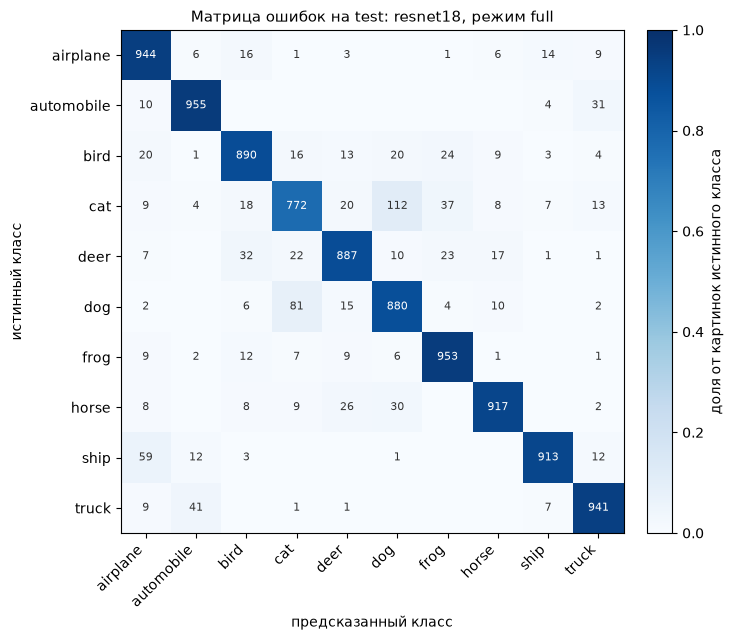

✔ recall посчитан для всех десяти классов
✔ средний recall совпадает с accuracy: классы в test представлены поровну
✔ поклассовый recall и худший класс сохранены в class_report.json


In [11]:
# Матрица ошибок получена при единственной оценке на test: строки — истинные классы, столбцы — предсказанные
cm = test_result["confusion_matrix"]
# Recall класса: верно распознанные картинки класса (диагональ) / все картинки этого класса (сумма строки)
recall = cm.diagonal() / cm.sum(axis=1)
# С каким классом каждый класс путают чаще всего: максимум в строке без диагонали
_off = cm.copy()
np.fill_diagonal(_off, 0)
_confused_with = _off.argmax(axis=1)

worst = int(recall.argmin())
class_report = {
    "backbone": BEST_BACKBONE,
    "mode": BEST_MODE,
    "n_test": len(test_ds),
    "test_accuracy": test_result["accuracy"],
    "recall": {CLASS_NAMES[k]: float(recall[k]) for k in range(NUM_CLASSES)},
    "support": {CLASS_NAMES[k]: int(cm[k].sum()) for k in range(NUM_CLASSES)},
    "most_confused_with": {
        CLASS_NAMES[k]: {"class": CLASS_NAMES[_confused_with[k]], "count": int(_off[k, _confused_with[k]])}
        for k in range(NUM_CLASSES)
    },
    "worst_class": CLASS_NAMES[worst],
    "worst_recall": float(recall[worst]),
    "best_class": CLASS_NAMES[int(recall.argmax())],
    "best_recall": float(recall.max()),
}
(ARTIFACTS / "class_report.json").write_text(json.dumps(class_report, ensure_ascii=False, indent=2), encoding="utf-8")

print(f"{'класс':12s} {'recall':>7s} {'верно':>6s} {'всего':>6s}   чаще всего путают с")
for k in np.argsort(recall):
    print(f"{CLASS_NAMES[k]:12s} {recall[k]:7.4f} {cm[k, k]:6d} {cm[k].sum():6d}   "
          f"{CLASS_NAMES[_confused_with[k]]} ({_off[k, _confused_with[k]]})")
print(f"\nХудший класс: {CLASS_NAMES[worst]}, recall {recall[worst]:.4f} при общей accuracy {test_result['accuracy']:.4f}")
print(f"Разброс recall между классами: от {recall.min():.4f} до {recall.max():.4f}")

# Матрица ошибок на test; цвет — доля от картинок истинного класса, числа — количество картинок
_share = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(_share, cmap="Blues", vmin=0, vmax=1)
for _t in range(NUM_CLASSES):
    for _p in range(NUM_CLASSES):
        if cm[_t, _p] > 0:
            ax.text(_p, _t, str(cm[_t, _p]), ha="center", va="center", fontsize=8,
                    color="white" if _share[_t, _p] > 0.5 else "#333333")
ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45, ha="right")
ax.set_yticks(range(NUM_CLASSES), CLASS_NAMES)
ax.set_xlabel("предсказанный класс")
ax.set_ylabel("истинный класс")
ax.set_title(f"Матрица ошибок на test: {BEST_BACKBONE}, режим {BEST_MODE}", fontsize=11)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="доля от картинок истинного класса")
plt.tight_layout()
plt.show()

check(len(class_report["recall"]) == NUM_CLASSES, "recall посчитан для всех десяти классов")
check(abs(recall.mean() - test_result["accuracy"]) < 1e-9,
      "средний recall совпадает с accuracy: классы в test представлены поровну")
check((ARTIFACTS / "class_report.json").exists(), "поклассовый recall и худший класс сохранены в class_report.json")

### Задание 9. Точность и стоимость обучения

*Вес: 1 балл.*

**Постановка.** Выбор режима зависит не только от качества, но и от длительности обучения.

Выполните следующие действия:
1. Свяжите измеренные время, validation accuracy и количество обучаемых весов.
2. Сохраните сопоставимую таблицу режимов.

**Результат.** efficiency_report.json с наблюдаемыми величинами.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


режим     обучаемых весов     доля  время, с  с/эпоху  память, МБ  val acc  macro-F1  время к frozen  прирост acc
frozen              5,130    0.05%      49.3      9.9         340   0.7945    0.7914           1.00x      +0.0000
partial         8,398,858   75.11%      49.9     10.0         437   0.8900    0.8902           1.01x      +0.0955
full           11,181,642  100.00%      67.7     13.5        1065   0.9220    0.9221           1.37x      +0.1275


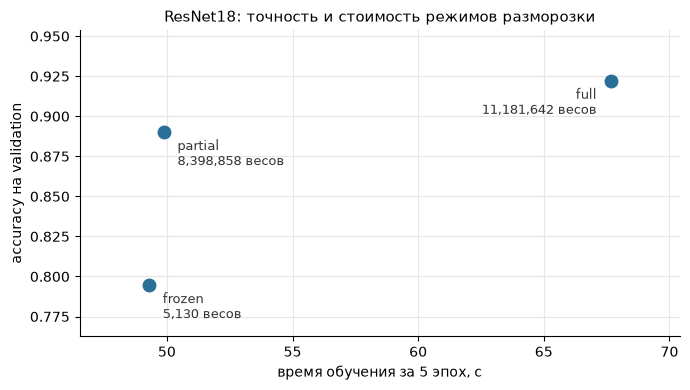

✔ в таблице все три режима
✔ режимы сопоставимы: одинаковое число эпох
✔ таблица режимов сохранена в efficiency_report.json


In [12]:
# Все величины измерены при обучении в задании про режимы fine-tuning; здесь они только сводятся в одну таблицу
_base = results["frozen"]
efficiency_rows = []
for mode in FREEZE_MODES:
    r = results[mode]
    efficiency_rows.append({
        "mode": mode,
        "trainable_params": r["trainable_params"],
        "trainable_fraction": r["trainable_params"] / r["total_params"],
        "epochs": r["epochs"],
        "train_time_sec": r["train_time_sec"],
        "sec_per_epoch": r["train_time_sec"] / r["epochs"],
        "peak_mem_mb": r["peak_mem_mb"],
        "val_accuracy": r["val_accuracy"],
        "val_macro_f1": r["val_macro_f1"],
        # Сравнение с самым дешёвым режимом frozen: во сколько раз дольше и на сколько точнее
        "time_vs_frozen": r["train_time_sec"] / _base["train_time_sec"],
        "accuracy_gain_vs_frozen": r["val_accuracy"] - _base["val_accuracy"],
    })

efficiency_report = {
    "backbone": "resnet18",
    "config": {**TRAIN_CONFIG, "epochs": EPOCHS},
    "device": DEVICE,
    "note": "время — только проходы обучения, без оценки на validation; одно измерение на режим",
    "best_by_val_accuracy": max(efficiency_rows, key=lambda row: row["val_accuracy"])["mode"],
    "fastest": min(efficiency_rows, key=lambda row: row["train_time_sec"])["mode"],
    "modes": efficiency_rows,
}
(ARTIFACTS / "efficiency_report.json").write_text(json.dumps(efficiency_report, ensure_ascii=False, indent=2), encoding="utf-8")

print(f"{'режим':8s} {'обучаемых весов':>16s} {'доля':>8s} {'время, с':>9s} {'с/эпоху':>8s} {'память, МБ':>11s} "
      f"{'val acc':>8s} {'macro-F1':>9s} {'время к frozen':>15s} {'прирост acc':>12s}")
for row in efficiency_rows:
    print(f"{row['mode']:8s} {row['trainable_params']:16,} {row['trainable_fraction']:8.2%} {row['train_time_sec']:9.1f} "
          f"{row['sec_per_epoch']:8.1f} {row['peak_mem_mb']:11.0f} {row['val_accuracy']:8.4f} {row['val_macro_f1']:9.4f} "
          f"{row['time_vs_frozen']:14.2f}x {row['accuracy_gain_vs_frozen']:+12.4f}")

# Качество против стоимости: каждая точка — один режим, подпись — режим и число обучаемых весов
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot([row["train_time_sec"] for row in efficiency_rows], [row["val_accuracy"] for row in efficiency_rows],
        linestyle="none", marker="o", markersize=9, color="#2a6f97")
_times = [row["train_time_sec"] for row in efficiency_rows]
for row in efficiency_rows:
    # Подпись ставится слева от крайней правой точки, чтобы не выходить за поле графика
    _right = row["train_time_sec"] == max(_times)
    ax.annotate(f"{row['mode']}\n{row['trainable_params']:,} весов", (row["train_time_sec"], row["val_accuracy"]),
                textcoords="offset points", xytext=(-10, -4) if _right else (10, -4),
                ha="right" if _right else "left", va="top", fontsize=9, color="#333333")
_pad = 0.15 * (max(_times) - min(_times))
ax.set_xlim(min(_times) - _pad, max(_times) + _pad)
ax.set_xlabel(f"время обучения за {EPOCHS} эпох, с")
ax.set_ylabel("accuracy на validation")
ax.set_title("ResNet18: точность и стоимость режимов разморозки", fontsize=11)
ax.grid(color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.margins(y=0.25)
plt.tight_layout()
plt.show()

check(len(efficiency_rows) == len(FREEZE_MODES), "в таблице все три режима")
check(len({row["epochs"] for row in efficiency_rows}) == 1, "режимы сопоставимы: одинаковое число эпох")
check((ARTIFACTS / "efficiency_report.json").exists(), "таблица режимов сохранена в efficiency_report.json")

### Задание 10. Анализ ошибок при максимальном сдвиге

*Вес: 1 балл.*

**Постановка.** Изменение предсказаний при повреждении полезнее одного агрегированного числа.

Выполните следующие действия:
1. Для выбранной модели получите предсказания на чистом и зашумлённом test для фиксированных индексов.
2. Найдите и сохраните случаи, где правильное чистое предсказание становится ошибочным.

**Результат.** shift_failures.json с индексами и предсказаниями на реальных изображениях.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


sigma = 0.3: accuracy 0.9052 на чистом test → 0.1022 на зашумлённом
верно → верно:      962
верно → ошибка:    8090   (эти случаи сохранены)
ошибка → верно:      60
ошибка → ошибка:    888

класс         потеряно  из верных     доля    ошибочных ответов в этот класс
automobile         955        955  100.00%                                 0
frog               953        953  100.00%                                 0
dog                880        880  100.00%                                 0
deer               887        887  100.00%                                 0
horse              917        917  100.00%                                 0
truck              941        941  100.00%                                 0
ship               911        913   99.78%                                 1
cat                769        772   99.61%                                30
bird               870        890   97.75%                               145
airplane             7        944    0.7

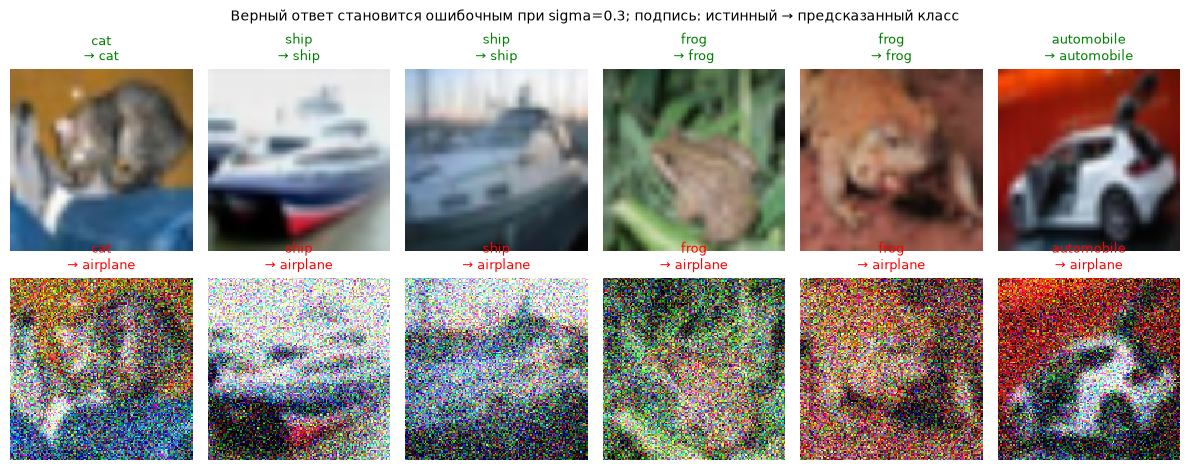

✔ в каждом сохранённом случае чистое предсказание верно, а зашумлённое ошибочно
✔ четыре группы переходов покрывают весь test
✔ сохранены все случаи «верно → ошибка»
✔ случаи сохранены в shift_failures.json


In [13]:
# Максимальный сдвиг — самая сильная из пяти интенсивностей шума; предсказания для неё уже получены в профиле
MAX_SIGMA = max(SIGMAS)
shifted_pred = sigma_preds[MAX_SIGMA]
# Фиксированные индексы: весь test в порядке test_idx, одинаковом для чистого и зашумлённого проходов
clean_ok = clean_pred == clean_true
shifted_ok = shifted_pred == clean_true
# Сбой из-за сдвига: на чистой картинке ответ был верным, на зашумлённой стал ошибочным
failure_pos = np.flatnonzero(clean_ok & ~shifted_ok)

transitions = {
    "correct_to_correct": int((clean_ok & shifted_ok).sum()),
    "correct_to_wrong": int((clean_ok & ~shifted_ok).sum()),
    "wrong_to_correct": int((~clean_ok & shifted_ok).sum()),
    "wrong_to_wrong": int((~clean_ok & ~shifted_ok).sum()),
}
# По каждому классу: сколько верных чистых ответов потеряно и какая это доля от верных чистых
_lost = np.bincount(clean_true[failure_pos], minlength=NUM_CLASSES)
_was_ok = np.bincount(clean_true[clean_ok], minlength=NUM_CLASSES)
# В какие классы уходят ошибочные ответы при шуме
_goes_to = np.bincount(shifted_pred[failure_pos], minlength=NUM_CLASSES)

shift_failures = {
    "backbone": BEST_BACKBONE,
    "mode": BEST_MODE,
    "noise": {"type": "gaussian", "sigma": MAX_SIGMA, "scale": "пиксели 0–1",
              "applied": f"после Resize до {IMG_SIZE} px, с обрезкой в 0–1", "seed": SEED},
    "index_meaning": "номер картинки в официальном test CIFAR-10",
    "n_test": len(test_ds),
    "clean_accuracy": float(clean_ok.mean()),
    "shifted_accuracy": float(shifted_ok.mean()),
    "transitions": transitions,
    "n_failures": int(len(failure_pos)),
    "failures_by_true_class": {
        CLASS_NAMES[k]: {"lost": int(_lost[k]), "clean_correct": int(_was_ok[k]),
                         "lost_fraction": float(_lost[k] / max(_was_ok[k], 1))}
        for k in range(NUM_CLASSES)
    },
    "failures_by_shifted_prediction": {CLASS_NAMES[k]: int(_goes_to[k]) for k in range(NUM_CLASSES)},
    "failures": [
        {"index": int(test_idx[pos]), "true": CLASS_NAMES[clean_true[pos]],
         "clean_pred": CLASS_NAMES[clean_pred[pos]], "noisy_pred": CLASS_NAMES[shifted_pred[pos]]}
        for pos in failure_pos
    ],
}
(ARTIFACTS / "shift_failures.json").write_text(json.dumps(shift_failures, ensure_ascii=False), encoding="utf-8")

print(f"sigma = {MAX_SIGMA}: accuracy {clean_ok.mean():.4f} на чистом test → {shifted_ok.mean():.4f} на зашумлённом")
print(f"верно → верно:   {transitions['correct_to_correct']:6d}")
print(f"верно → ошибка:  {transitions['correct_to_wrong']:6d}   (эти случаи сохранены)")
print(f"ошибка → верно:  {transitions['wrong_to_correct']:6d}")
print(f"ошибка → ошибка: {transitions['wrong_to_wrong']:6d}")

print(f"\n{'класс':12s} {'потеряно':>9s} {'из верных':>10s} {'доля':>8s}   {'ошибочных ответов в этот класс':>31s}")
for k in np.argsort(-_lost / np.maximum(_was_ok, 1)):
    print(f"{CLASS_NAMES[k]:12s} {_lost[k]:9d} {_was_ok[k]:10d} {_lost[k] / max(_was_ok[k], 1):8.2%}   {_goes_to[k]:31d}")

# Примеры сбоев из первого батча test: сверху чистая картинка, снизу она же с шумом, использованным при оценке
_n_show = 6
_xb, _ = next(iter(test_loader))
_clean = _xb.to(DEVICE)
_noisy = add_gaussian_noise(_clean, MAX_SIGMA, torch.Generator(device=DEVICE).manual_seed(SEED))
_examples = failure_pos[failure_pos < len(_xb)][:_n_show]
if len(_examples) > 0:
    fig, axes = plt.subplots(2, len(_examples), figsize=(2 * len(_examples), 4.8), squeeze=False)
    for _row, (_batch, _pred) in enumerate([(_clean, clean_pred), (_noisy, shifted_pred)]):
        _images = (_batch * _STD + _MEAN).clamp(0, 1).permute(0, 2, 3, 1).cpu().numpy()
        for _col, _pos in enumerate(_examples):
            axes[_row, _col].imshow(_images[_pos], interpolation="nearest")
            axes[_row, _col].set_title(f"{CLASS_NAMES[clean_true[_pos]]}\n→ {CLASS_NAMES[_pred[_pos]]}", fontsize=9,
                                       color="green" if _pred[_pos] == clean_true[_pos] else "red")
            axes[_row, _col].axis("off")
    fig.suptitle(f"Верный ответ становится ошибочным при sigma={MAX_SIGMA}; подпись: истинный → предсказанный класс",
                 fontsize=10)
    plt.tight_layout()
    plt.show()

check(all(f["clean_pred"] == f["true"] and f["noisy_pred"] != f["true"] for f in shift_failures["failures"]),
      "в каждом сохранённом случае чистое предсказание верно, а зашумлённое ошибочно")
check(sum(transitions.values()) == len(test_ds), "четыре группы переходов покрывают весь test")
check(len(shift_failures["failures"]) == transitions["correct_to_wrong"], "сохранены все случаи «верно → ошибка»")
check((ARTIFACTS / "shift_failures.json").exists(), "случаи сохранены в shift_failures.json")

### Задание 11 (дополнительное). Творческий бонус: новый тип сдвига

*Вес: 1 дополнительный балл.*

**Постановка.** Не все повреждения изображений похожи на гауссовский шум.

Выполните следующие действия:
1. Выберите воспроизводимое фотометрическое или геометрическое преобразование test-изображений.
2. Сравните точность с чистым test и приведите три конкретных примера изменения предсказания.

**Результат.** bonus_shift.json с описанием преобразования, метрикой и индексами примеров.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


**Геометрические преобразования** меняют положение и форму объекта на картинке, не трогая цвета пикселей: отражение, поворот, сдвиг, обрезка, масштабирование.

**Фотометрические преобразования** меняют цвета и яркость пикселей, не трогая геометрию: яркость, контраст, насыщенность, размытие, шум.


accuracy на чистом test:        0.9052
accuracy после поворота на 90°: 0.4632
падение accuracy:               0.4420
для сравнения, гауссовский шум sigma=0.1: 0.3144
предсказание изменилось у 5248 картинок из 10000: верно → ошибка 4642, ошибка → верно 222

класс         recall чистый  после поворота  падение
horse                0.9170          0.0930   0.8240
automobile           0.9550          0.1340   0.8210
ship                 0.9130          0.1720   0.7410
deer                 0.8870          0.4060   0.4810
dog                  0.8800          0.5090   0.3710
airplane             0.9440          0.6060   0.3380
bird                 0.8900          0.5890   0.3010
truck                0.9410          0.7260   0.2150
cat                  0.7720          0.5660   0.2060
frog                 0.9530          0.8310   0.1220

Три примера изменения предсказания:
  картинка 1: истинный класс ship, до поворота ship, после truck
  картинка 2: истинный класс ship, до поворота ship, после

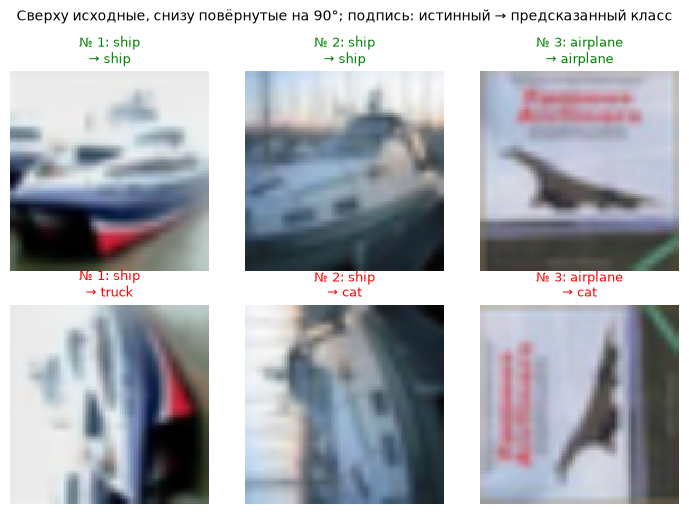

✔ приведены три конкретных примера изменения предсказания
✔ в каждом примере предсказание действительно изменилось
✔ поворот на 90° и обратно возвращает исходную картинку: преобразование точное
✔ описание преобразования, метрика и индексы примеров сохранены в bonus_shift.json


In [14]:
# Геометрический сдвиг: поворот картинки на 90° против часовой стрелки.
# Преобразование точное (пиксели переставляются без интерполяции) и не содержит случайности, поэтому воспроизводимо без seed.
ROT_K = 1  # число поворотов на 90°


def rotate90(xb, k=ROT_K):
    """Поворот батча (N, C, H, W) на k·90° против часовой стрелки; нормализация по каналам при этом не нарушается."""
    return torch.rot90(xb, k=k, dims=(2, 3))


@torch.no_grad()
def predict_transformed(model, loader, transform):
    """Предсказания модели на картинках, к которым применено преобразование transform."""
    model.eval()
    y_pred = []
    for xb, _ in loader:
        y_pred.append(model(transform(xb.to(DEVICE, non_blocking=True))).argmax(dim=1).cpu().numpy())
    return np.concatenate(y_pred)


# Те же test-картинки в том же порядке, что и при чистой оценке
rot_pred = predict_transformed(final_model, test_loader, rotate90)
clean_ok = clean_pred == clean_true
rot_ok = rot_pred == clean_true
rot_acc = float(rot_ok.mean())
changed = clean_pred != rot_pred

# Recall по классам до и после поворота: какие классы зависят от ориентации сильнее
_clean_recall = np.array([clean_ok[clean_true == k].mean() for k in range(NUM_CLASSES)])
_rot_recall = np.array([rot_ok[clean_true == k].mean() for k in range(NUM_CLASSES)])

# Три конкретных примера: верный ответ на чистой картинке сменился ошибочным; берутся первые по порядку test
example_pos = np.flatnonzero(clean_ok & ~rot_ok)[:3]
if len(example_pos) < 3:
    example_pos = np.flatnonzero(changed)[:3]

bonus_shift = {
    "backbone": BEST_BACKBONE,
    "mode": BEST_MODE,
    "transform": {
        "type": "geometric",
        "name": "поворот на 90° против часовой стрелки",
        "implementation": f"torch.rot90(x, k={ROT_K}, dims=(2, 3)) после Resize до {IMG_SIZE} px и нормализации",
        "reproducibility": "детерминированное преобразование без случайности и интерполяции",
    },
    "index_meaning": "номер картинки в официальном test CIFAR-10",
    "n_test": len(test_ds),
    "clean_accuracy": clean_acc,
    "shifted_accuracy": rot_acc,
    "accuracy_drop": clean_acc - rot_acc,
    "clean_macro_f1": shift_metrics["clean_macro_f1"],
    "shifted_macro_f1": float(f1_score(clean_true, rot_pred, labels=_labels, average="macro", zero_division=0)),
    "n_changed_predictions": int(changed.sum()),
    "n_correct_to_wrong": int((clean_ok & ~rot_ok).sum()),
    "n_wrong_to_correct": int((~clean_ok & rot_ok).sum()),
    "recall_by_class": {
        CLASS_NAMES[k]: {"clean": float(_clean_recall[k]), "shifted": float(_rot_recall[k])} for k in range(NUM_CLASSES)
    },
    "examples": [
        {"index": int(test_idx[pos]), "true": CLASS_NAMES[clean_true[pos]],
         "clean_pred": CLASS_NAMES[clean_pred[pos]], "shifted_pred": CLASS_NAMES[rot_pred[pos]]}
        for pos in example_pos
    ],
}
(ARTIFACTS / "bonus_shift.json").write_text(json.dumps(bonus_shift, ensure_ascii=False, indent=2), encoding="utf-8")

print(f"accuracy на чистом test:        {clean_acc:.4f}")
print(f"accuracy после поворота на 90°: {rot_acc:.4f}")
print(f"падение accuracy:               {clean_acc - rot_acc:.4f}")
print(f"для сравнения, гауссовский шум sigma={NOISE_SIGMA}: {noisy_acc:.4f}")
print(f"предсказание изменилось у {int(changed.sum())} картинок из {len(test_ds)}: "
      f"верно → ошибка {bonus_shift['n_correct_to_wrong']}, ошибка → верно {bonus_shift['n_wrong_to_correct']}")

print(f"\n{'класс':12s} {'recall чистый':>14s} {'после поворота':>15s} {'падение':>8s}")
for k in np.argsort(_rot_recall - _clean_recall):
    print(f"{CLASS_NAMES[k]:12s} {_clean_recall[k]:14.4f} {_rot_recall[k]:15.4f} {_clean_recall[k] - _rot_recall[k]:8.4f}")

print("\nТри примера изменения предсказания:")
for ex in bonus_shift["examples"]:
    print(f"  картинка {ex['index']}: истинный класс {ex['true']}, до поворота {ex['clean_pred']}, после {ex['shifted_pred']}")

# Те же три примера: сверху исходная картинка, снизу повёрнутая — в том виде, в каком её получила модель
if len(example_pos) > 0:
    _batch = torch.stack([test_ds[int(pos)][0] for pos in example_pos]).to(DEVICE)
    fig, axes = plt.subplots(2, len(example_pos), figsize=(2.4 * len(example_pos), 5.2), squeeze=False)
    for _row, (_x, _pred) in enumerate([(_batch, clean_pred), (rotate90(_batch), rot_pred)]):
        _images = (_x * _STD + _MEAN).clamp(0, 1).permute(0, 2, 3, 1).cpu().numpy()
        for _col, _pos in enumerate(example_pos):
            axes[_row, _col].imshow(_images[_col], interpolation="nearest")
            axes[_row, _col].set_title(f"№ {int(test_idx[_pos])}: {CLASS_NAMES[clean_true[_pos]]}\n→ {CLASS_NAMES[_pred[_pos]]}",
                                       fontsize=9, color="green" if _pred[_pos] == clean_true[_pos] else "red")
            axes[_row, _col].axis("off")
    fig.suptitle("Сверху исходные, снизу повёрнутые на 90°; подпись: истинный → предсказанный класс", fontsize=10)
    plt.tight_layout()
    plt.show()

check(len(bonus_shift["examples"]) == 3, "приведены три конкретных примера изменения предсказания")
check(all(ex["clean_pred"] != ex["shifted_pred"] for ex in bonus_shift["examples"]),
      "в каждом примере предсказание действительно изменилось")
_x0 = test_ds[0][0].unsqueeze(0)
check(torch.equal(rotate90(rotate90(_x0), k=3), _x0), "поворот на 90° и обратно возвращает исходную картинку: преобразование точное")
check((ARTIFACTS / "bonus_shift.json").exists(), "описание преобразования, метрика и индексы примеров сохранены в bonus_shift.json")

## Анализ результатов

Все числа ниже получены в полном режиме (`FAST_DEV_RUN=False`) и взяты из файлов в `artifacts/lab1/`.

### Бюджет

| Параметр | Значение |
|---|---|
| Данные | CIFAR-10: 10 000 train и 2 000 validation (стратифицированно, из обучающей части), 10 000 test (весь официальный test) |
| Размер входа | 128×128, нормализация ImageNet |
| Аугментации train | случайный сдвиг до 16 пикселей, отражение слева направо |
| Обучение | 5 эпох, batch 128, AdamW, lr 1e-3 для головы и 1e-4 для backbone, weight decay 1e-4, FP32 |
| Воспроизводимость | seed 42; одинаковые начальные веса головы, порядок батчей и аугментации во всех запусках |
| Выбор | эпоха, режим и архитектура — по macro-F1 на validation; test использован один раз, после выбора |

Backbone — основная часть нейросети, которая извлекает признаки из входных данных; обычно её берут предобученной, а сверху ставят голову под конкретную задачу.

### Режимы разморозки ResNet18 (validation)

| Режим | Обучаемых весов | Доля | Время, с | Память, МБ | Accuracy | Macro-F1 | Лучшая эпоха |
|---|---|---|---|---|---|---|---|
| frozen | 5 130 | 0.05 % | 49.3 | 340 | 0.7945 | 0.7914 | 4 |
| partial | 8 398 858 | 75.1 % | 49.9 | 437 | 0.8900 | 0.8902 | 5 |
| full | 11 181 642 | 100 % | 67.7 | 1 065 | 0.9220 | 0.9221 | 4 |

Это сравнение служит контролируемой ablation: данные, число эпох, оптимизатор и seed одинаковы, меняется только множество обучаемых параметров.

- **Frozen недообучен.** Accuracy на train (0.80) почти равна accuracy на validation (0.79): признаки ImageNet без адаптации плохо подходят к увеличенным картинкам 32×32, и одна линейная голова этого не исправляет.
- **Partial даёт основной прирост почти бесплатно.** Разморозка `layer4` добавляет 9.6 п. п. accuracy при том же времени (49.9 против 49.3 с) и небольшом росте памяти.
- **Full добавляет ещё 3.2 п. п.**, но стоит на 36 % больше времени и в 2.4 раза больше памяти, чем partial.
- **Full начинает переобучаться к пятой эпохе.** Loss на train продолжает падать (0.133 → 0.100), а на validation перестаёт (0.2640 → 0.2645), macro-F1 снижается с 0.9221 до 0.9193. Поэтому сохранены веса четвёртой эпохи.
- **Число обучаемых весов не предсказывает стоимость.** У partial их в 1 600 раз больше, чем у frozen, а время то же: `layer4` содержит 75 % весов сети, но работает с картами признаков 4×4.

### Сравнение архитектур (validation, режим full)

| Backbone | Параметров | Время, с | Память, МБ | Accuracy | Macro-F1 | Loss |
|---|---|---|---|---|---|---|
| ResNet18 | 11 181 642 | 67.7 | 1 065 | 0.9220 | 0.9221 | 0.264 |
| EfficientNet-B0 | 4 020 358 | 90.9 | 3 662 | 0.9180 | 0.9180 | 0.231 |

По правилу выбора взята ResNet18, но разница в 0.4 п. п. меньше погрешности оценки на 2 000 картинок (около ±1.2 п. п.), так что по качеству модели неразличимы. У EfficientNet-B0 loss на validation ниже, и её метрики ещё росли на пятой эпохе; при большем числе эпох результат мог бы измениться. По стоимости различие однозначное: EfficientNet-B0 при почти втрое меньшем числе параметров обучалась на 34 % дольше и заняла в 3.4 раза больше памяти.

### Отложенный test (ResNet18, full)

Accuracy 0.9052, macro-F1 0.9049, loss 0.292. Это на 1.7 п. п. ниже, чем на validation (0.9220). Разница согласуется с тем, что validation-оценка завышена многократным выбором и сама измерена с погрешностью; погрешность test-оценки на 10 000 картинок — около ±0.6 п. п.

### Ошибки модели по классам

Из 10 000 test-картинок модель ошиблась на 948. Recall по классам меняется от 0.772 до 0.955, то есть общая accuracy скрывает разброс в 18 п. п.

| Класс | Recall | Чаще всего путают с |
|---|---|---|
| cat | 0.772 | dog (112) |
| dog | 0.880 | cat (81) |
| deer | 0.887 | bird (32) |
| bird | 0.890 | frog (24) |
| ship | 0.913 | airplane (59) |
| horse | 0.917 | dog (30) |
| truck | 0.941 | automobile (41) |
| airplane | 0.944 | bird (16) |
| frog | 0.953 | bird (12) |
| automobile | 0.955 | truck (31) |

Основные ошибки происходят внутри пар похожих классов: cat–dog (193 ошибки в обе стороны), automobile–truck (72), ship–airplane. Худший класс — cat: почти каждая девятая кошка названа собакой.

### Устойчивость к гауссовскому шуму

| Sigma | Accuracy | Macro-F1 | Падение accuracy |
|---|---|---|---|
| 0 (чистый test) | 0.9052 | 0.9049 | — |
| 0.02 | 0.8564 | 0.8573 | 0.049 |
| 0.05 | 0.6783 | 0.6873 | 0.227 |
| 0.10 | 0.3144 | 0.2804 | 0.591 |
| 0.20 | 0.1585 | 0.0794 | 0.747 |
| 0.30 | 0.1022 | 0.0235 | 0.803 |

- **Модель очень чувствительна к шуму.** Уже при слабом шуме с sigma 0.02 теряется 4.9 п. п.; при 0.1 accuracy падает почти втрое.
- **При сильном шуме модель сводится к одному классу.** При sigma 0.3 из 9 052 верных ответов ошибочными стали 8 090, и в 7 914 случаях модель ответила «airplane». Сами самолёты почти не пострадали: потеряно 7 верных ответов из 944. Accuracy 0.10 здесь — не случайное угадывание, а ответ одним классом, что видно по macro-F1 0.024.
- **Вероятная причина** (не проверялась): картинки, увеличенные с 32 до 128 пикселей, гладкие, а попиксельный шум на 128×128 добавляет мелкозернистую структуру, которой в обучении не было; шумовых аугментаций модель не видела.

### Поворот на 90° (бонус)

Accuracy падает с 0.9052 до 0.4632, macro-F1 — до 0.4323; 4 642 верных ответа стали ошибочными, 222 ошибочных — верными. Классы страдают неодинаково:

| Класс | Recall до | Recall после |
|---|---|---|
| horse | 0.917 | 0.093 |
| automobile | 0.955 | 0.134 |
| ship | 0.913 | 0.172 |
| deer | 0.887 | 0.406 |
| dog | 0.880 | 0.509 |
| cat | 0.772 | 0.566 |
| bird | 0.890 | 0.589 |
| airplane | 0.944 | 0.606 |
| truck | 0.941 | 0.726 |
| frog | 0.953 | 0.831 |

Сильнее всего теряют классы, которые на фотографиях почти всегда сняты в одном положении (лошадь, автомобиль, корабль); слабее — те, что встречаются в разных ракурсах (лягушка). Примеры: картинка № 1 — ship → truck, № 2 — ship → cat, № 3 — airplane → cat. Поворот на 90° только переставляет пиксели: набор значений яркости остаётся тем же, меняется лишь их расположение. Это геометрический сдвиг, а шум — фотометрический (он меняет сами значения), но потери сопоставимы с шумом sigma 0.05–0.1.

### Ограничения

- **Сокращённый бюджет.** Использовано 10 000 из 50 000 обучающих картинок, 5 эпох, вход 128 вместо 224 пикселей. Абсолютные значения метрик ниже достижимых на полном CIFAR-10.
- **Один запуск на конфигурацию.** Все сравнения сделаны при одном seed, время измерено по одному разу. Различия меньше примерно 1 п. п. по качеству и нескольких секунд по времени нельзя считать значимыми; это касается и выбора между ResNet18 и EfficientNet-B0.
- **Гиперпараметры не подбирались.** Learning rate и число эпох заданы заранее и одинаковы для всех моделей; возможно, для каждого режима оптимальны свои.
- **EfficientNet-B0 обучена только в режиме full**, выбранном по ResNet18.
- **Шум добавлялся после увеличения картинки**, один рисунок шума на все значения sigma. При шуме на исходных 32×32 или при другом seed числа были бы другими.
- **Результаты `FAST_DEV_RUN=True` в отчёт не входят:** этот режим служит только проверкой исполнения.

## Выводы

1. **Чем больше слоёв дообучается, тем выше качество, но прирост убывает.** На 10 000 картинках CIFAR-10 за 5 эпох ResNet18 дала на validation accuracy 0.79 при замороженном backbone, 0.89 при размороженном последнем блоке и 0.92 при полном fine-tuning (`metrics.json`). Первый шаг разморозки даёт 9.6 п. п., второй — 3.2 п. п.

2. **Разморозка одного последнего блока даёт большую часть прироста почти без затрат.** Переход от frozen к partial поднял accuracy на validation с 0.79 до 0.89 при том же времени обучения (49.3 и 49.9 с). Переход от partial к full добавил ещё 3.2 п. п., но потребовал на 36 % больше времени и в 2.4 раза больше памяти (`efficiency_report.json`). Самый точный режим — full, и он выбран итоговым, но по соотношению качества и затрат выгоднее partial. Число обучаемых весов при этом плохо предсказывает время обучения: у partial их в 1 600 раз больше, чем у frozen, а время то же, потому что 75 % весов сети лежат в последнем блоке, где вычислений мало (`param_report.json`).

3. **Выбранная модель — ResNet18 с полным fine-tuning: accuracy 0.9052 и macro-F1 0.9049 на отложенном test** (`test_metrics.json`). EfficientNet-B0 при том же бюджете показала на validation неотличимое качество (0.918 против 0.922), но обучалась дольше и заняла в 3.4 раза больше памяти (`backbone_comparison.json`). Меньшее число параметров не означает меньшую стоимость обучения.

4. **Средняя точность скрывает слабые классы.** Recall меняется от 0.772 у кошек до 0.955 у автомобилей; основная часть ошибок приходится на пары похожих классов, прежде всего cat–dog (`class_report.json`).

5. **Высокая точность на чистых данных не означает устойчивости.** Гауссовский шум с sigma 0.1 снижает accuracy с 0.91 до 0.31, а при sigma 0.3 модель почти на всё отвечает одним классом (`sigma_sensitivity.json`, `shift_failures.json`). Поворот на 90° снижает accuracy до 0.46, причём у лошадей, автомобилей и кораблей recall падает ниже 0.2 (`bonus_shift.json`). Модель опирается на признаки, привязанные к условиям обучения: гладким картинкам и привычной ориентации объектов.

6. **Практическое следствие.** Для применения вне условий обучения такую модель нужно дообучать с аугментациями под ожидаемые искажения (шум, повороты) и проверять на сдвинутых данных, а не только на чистом test. Выводы получены при одном запуске на сокращённом бюджете; различия меньше 1 п. п. требуют проверки на нескольких seed.